__лабораторная работа N2:__ предварительная обработка данных

__цель:__ изучить методы и средства EDA/Exploratory Data Analysis

__порядок выполнения:__ выполните задания представленные ниже

__литература__

?

# выберите источник и загрузите данные для анализа

In [ ]:
from sklearn import datasets as ds
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = ds.load_wine() # выбран датасет вина

# изучите структуру загруженных данных

In [2]:
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target
df.head()

print("Типы признаков:")
print(df.dtypes)

print("\n\nСмысловое (словесное) описание:")
print(data.DESCR)

Типы признаков:
alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
target                            int64
dtype: object


Смысловое (словесное) описание:
.. _wine_dataset:

Wine recognition dataset
------------------------

**Data Set Characteristics:**

:Number of Instances: 178
:Number of Attributes: 13 numeric, predictive attributes and the class
:Attribute Information:
    - Alcohol
    - Malic acid
    - Ash
    - Alcalinity of ash
    - Magnesium
    - Total phenols
    - Flavanoids
    - Nonflavanoid phenols
    - Pro

# выполните проверку на пропуски в данных

In [3]:
missing = df.isnull().sum()
print("Всего пропусков в датасете:", df.isnull().sum().sum())
print("\nПо столбцам:")
print(missing[missing > 0] if missing.sum() else "  — пропусков нет ни в одном столбце")

Всего пропусков в датасете: 0

По столбцам:
  — пропусков нет ни в одном столбце


# выполните проверку на дубликаты записей

In [4]:
n_dup_full = df.duplicated().sum()
print("Полных дубликатов строк:", n_dup_full)

if n_dup_full:
    display(df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(20))

Полных дубликатов строк: 0


# если данные размечены, то проведите проверку на противоречивость разметки и сбалансированность классов


In [ ]:
# ПРОВЕРКА НА ПРОТИВОРЕЧИВОСТЬ
label_check = (
    df.groupby(data.feature_names, dropna=False)['target']
      .agg(['nunique', 'count'])
      .reset_index()
)

conflicts = label_check[label_check['nunique'] > 1]
print("Групп объектов с одинаковыми признаками:", len(label_check))
print("Из них с противоречивой разметкой:", len(conflicts))

if len(conflicts):
    display(conflicts)
else:
    print("Противоречивой разметки не обнаружено")

# СБАЛАНСИРОВАННОСТЬ КЛАССОВ
class_counts = df['target'].value_counts().sort_index()
class_pct = (class_counts / len(df) * 100).round(2)

balance = pd.DataFrame({
    'cultivar': [data.target_names[i] for i in class_counts.index],
    'count': class_counts.values,
    'percent, %': class_pct.values,
})
balance.index.name = 'class'
print(balance)

# Коэффициент дисбаланса
imbalance_ratio = class_counts.max() / class_counts.min()
print(f"\nКоэф. дисбаланса (max/min): {imbalance_ratio:.2f}")

Групп объектов с одинаковыми признаками: 178
Из них с противоречивой разметкой: 0
Противоречивой разметки не обнаружено

Коэф. дисбаланса (max/min): 1.48


# посчитайте статистические статистические характеристики и визуализируйте результаты


In [6]:
# корреляции, распределения, персентили, визуализация признаков попарно и/или PCA
stats = df[data.feature_names].describe().T
stats['range'] = stats['max'] - stats['min']
stats['cv'] = (stats['std'] / stats['mean']).round(3)   # коэф. вариации
print("Стат. характеристики")
stats.round(3)

Стат. характеристики


,count,mean,std,min,25%,50%,75%,max,range,cv
alcohol,178.0,13.001,0.812,11.03,12.362,13.050,13.678,14.83,3.80,0.062
malic_acid,178.0,2.336,1.117,0.74,1.602,1.865,3.082,5.80,5.06,0.478
ash,178.0,2.367,0.274,1.36,2.210,2.360,2.558,3.23,1.87,0.116
alcalinity_of_ash,178.0,19.495,3.340,10.60,17.200,19.500,21.500,30.00,19.40,0.171
magnesium,178.0,99.742,14.282,70.00,88.000,98.000,107.000,162.00,92.00,0.143
total_phenols,178.0,2.295,0.626,0.98,1.742,2.355,2.800,3.88,2.90,0.273
flavanoids,178.0,2.029,0.999,0.34,1.205,2.135,2.875,5.08,4.74,0.492
nonflavanoid_phenols,178.0,0.362,0.124,0.13,0.270,0.340,0.438,0.66,0.53,0.344
proanthocyanins,178.0,1.591,0.572,0.41,1.250,1.555,1.950,3.58,3.17,0.360
color_intensity,178.0,5.058,2.318,1.28,3.220,4.690,6.200,13.00,11.72,0.458


In [7]:
print("Квантили")
quantiles = [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
q_table = df[data.feature_names].quantile(quantiles).T
q_table.round(3)

Квантили


,0.01,0.05,0.10,0.25,0.50,0.75,0.90,0.95,0.99
alcohol,11.441,11.658,11.933,12.362,13.050,13.678,14.100,14.222,14.473
malic_acid,0.898,1.061,1.247,1.602,1.865,3.082,3.983,4.456,5.542
ash,1.700,1.920,2.000,2.210,2.360,2.558,2.700,2.742,2.989
alcalinity_of_ash,11.354,14.770,16.000,17.200,19.500,21.500,24.000,25.000,28.500
magnesium,78.000,80.850,85.000,88.000,98.000,107.000,118.000,124.300,141.760
total_phenols,1.138,1.380,1.471,1.742,2.355,2.800,3.044,3.274,3.596
flavanoids,0.470,0.546,0.607,1.205,2.135,2.875,3.233,3.498,3.791
nonflavanoid_phenols,0.140,0.190,0.217,0.270,0.340,0.438,0.530,0.600,0.630
proanthocyanins,0.420,0.730,0.854,1.250,1.555,1.950,2.305,2.709,3.034
color_intensity,1.863,2.114,2.549,3.220,4.690,6.200,8.530,9.598,11.018


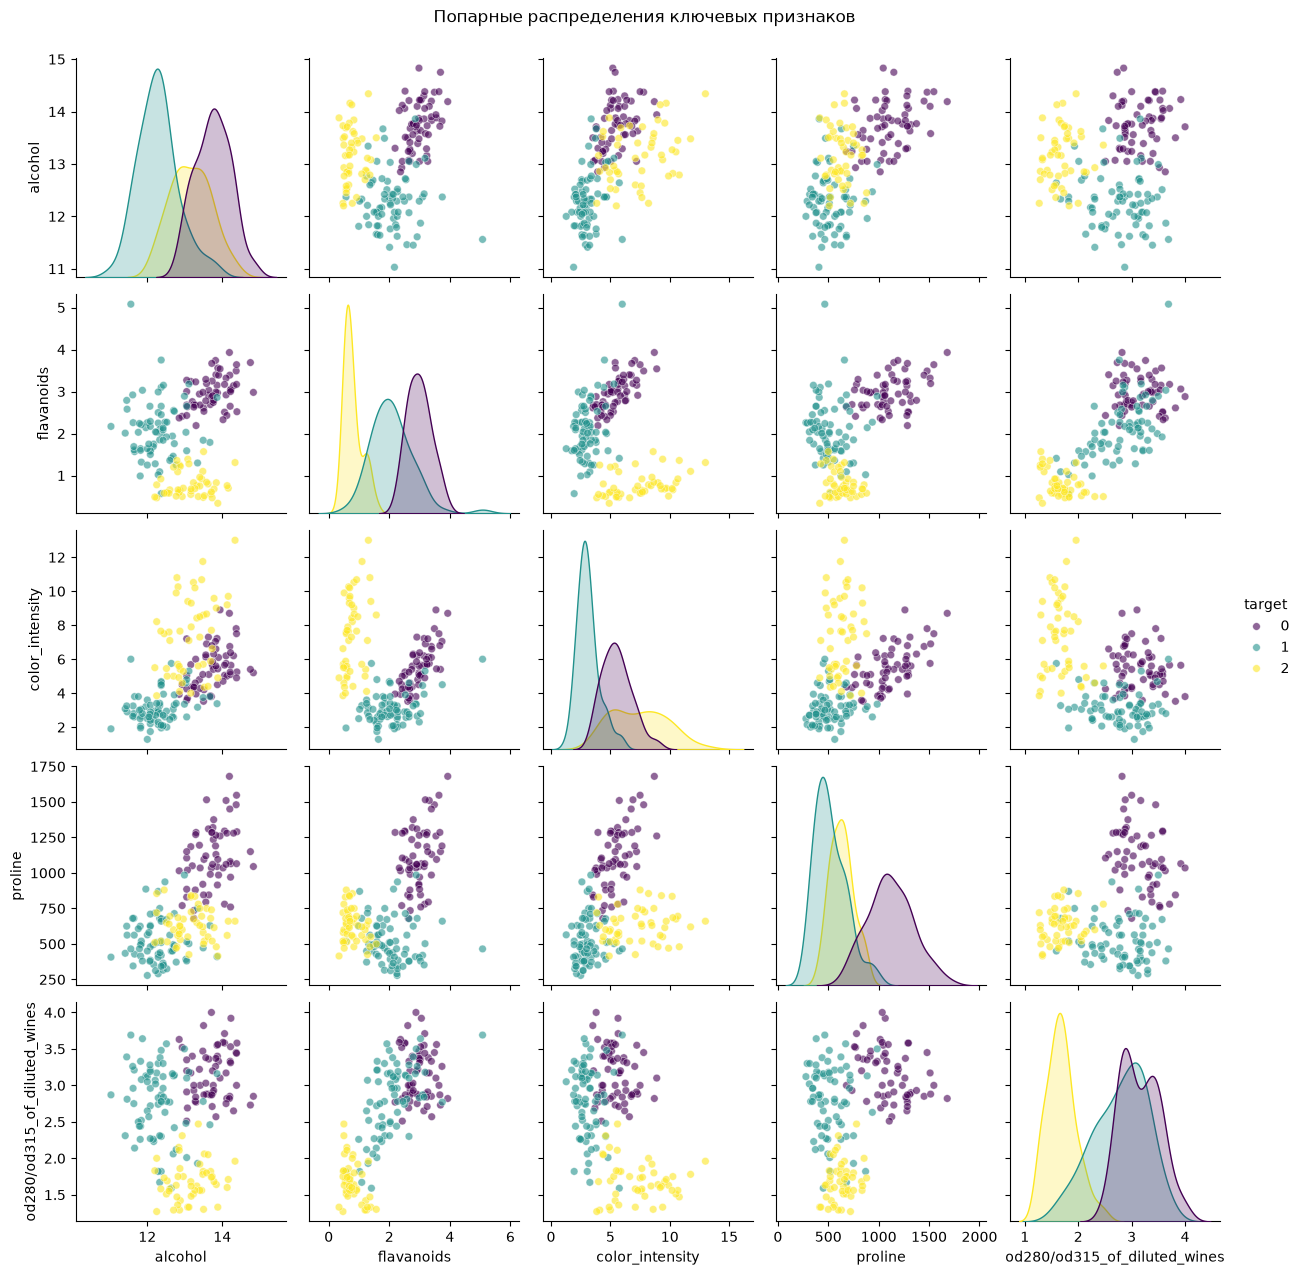

In [8]:
key_features = ['alcohol', 'flavanoids', 'color_intensity',
                'proline', 'od280/od315_of_diluted_wines']
sns.pairplot(df[key_features + ['target']],
             hue='target', palette='viridis', diag_kind='kde',
             plot_kws={'alpha': 0.6, 's': 30})
plt.suptitle('Попарные распределения ключевых признаков', y=1.02)
plt.show()

# проведите поиск аномалий

In [9]:
num_cols = data.feature_names

Q1 = df[num_cols].quantile(0.25)
Q3 = df[num_cols].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outlier_mask_iqr = (df[num_cols] < lower) | (df[num_cols] > upper)

iqr_report = pd.DataFrame({
    'n_outliers': outlier_mask_iqr.sum(),
    'percent, %': (outlier_mask_iqr.mean() * 100).round(2),
    'lower_bound': lower.round(2),
    'upper_bound': upper.round(2),
}).sort_values('n_outliers', ascending=False)

print("Выбросы по каждому признаку (IQR):")
print(iqr_report)

rows_iqr = outlier_mask_iqr.any(axis=1).sum()
print(f"\nСтрок хотя бы с одним выбросом: {rows_iqr} ({rows_iqr/len(df)*100:.1f} %)")

Выбросы по каждому признаку (IQR):
                              n_outliers  percent, %  lower_bound  upper_bound
magnesium                              4        2.25        59.50       135.50
alcalinity_of_ash                      4        2.25        10.75        27.95
color_intensity                        4        2.25        -1.25        10.67
malic_acid                             3        1.69        -0.62         5.30
ash                                    3        1.69         1.69         3.08
proanthocyanins                        2        1.12         0.20         3.00
hue                                    1        0.56         0.28         1.63
alcohol                                0        0.00        10.39        15.65
total_phenols                          0        0.00         0.16         4.39
nonflavanoid_phenols                   0        0.00         0.02         0.69
flavanoids                             0        0.00        -1.30         5.38
od280/od315_of_di

# выводы

In [10]:
summary = (
    f"Датасет load_wine чистый ({missing.sum()} пропусков, {n_dup_full} полных дубликатов), ",
    f"полностью размечен без противоречий. {len(data.feature_names)} числовых признаков, ",
    f"{len(class_counts)} класса со слабым дисбалансом (ratio = {imbalance_ratio:.2f}). ",
    f"Основные особенности: разный масштаб признаков, мультиколлинеарность ",
    f"фенольной группы, частичное перекрытие классов 1 и 2. ",
    f"Аномалии малочисленны и представляют реальную химическую вариативность — ",
    f"удалять их не рекомендуется. Данные готовы к этапу моделирования."
)


print('\n'.join(summary))

Датасет load_wine чистый (0 пропусков, 0 полных дубликатов), 
полностью размечен без противоречий. 13 числовых признаков, 
3 класса со слабым дисбалансом (ratio = 1.48). 
Основные особенности: разный масштаб признаков, мультиколлинеарность 
фенольной группы, частичное перекрытие классов 1 и 2. 
Аномалии малочисленны и представляют реальную химическую вариативность — 
удалять их не рекомендуется. Данные готовы к этапу моделирования.
